# Project: Identify Customer Segments

In this project, you will apply unsupervised learning techniques to identify segments of the population that form the core customer base for a mail-order sales company in Germany. These segments can then be used to direct marketing campaigns towards audiences that will have the highest expected rate of returns. The data that you will use has been provided by our partners at Bertelsmann Arvato Analytics, and represents a real-life data science task.

This notebook will help you complete this task by providing a framework within which you will perform your analysis steps. In each step of the project, you will see some text describing the subtask that you will perform, followed by one or more code cells for you to complete your work. **Feel free to add additional code and markdown cells as you go along so that you can explore everything in precise chunks.** The code cells provided in the base template will outline only the major tasks, and will usually not be enough to cover all of the minor tasks that comprise it.

It should be noted that while there will be precise guidelines on how you should handle certain tasks in the project, there will also be places where an exact specification is not provided. **There will be times in the project where you will need to make and justify your own decisions on how to treat the data.** These are places where there may not be only one way to handle the data. In real-life tasks, there may be many valid ways to approach an analysis task. One of the most important things you can do is clearly document your approach so that other scientists can understand the decisions you've made.

At the end of most sections, there will be a Markdown cell labeled **Discussion**. In these cells, you will report your findings for the completed section, as well as document the decisions that you made in your approach to each subtask. **Your project will be evaluated not just on the code used to complete the tasks outlined, but also your communication about your observations and conclusions at each stage.**

In [1]:
# import libraries here; add more as necessary
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# magic word for producing visualizations in notebook
%matplotlib inline

pd.options.display.max_rows = None
pd.options.display.max_columns = None

### Step 0: Load the Data

There are four files associated with this project (not including this one):

- `Udacity_AZDIAS_Subset.csv`: Demographics data for the general population of Germany; 891211 persons (rows) x 85 features (columns).
- `Udacity_CUSTOMERS_Subset.csv`: Demographics data for customers of a mail-order company; 191652 persons (rows) x 85 features (columns).
- `Data_Dictionary.md`: Detailed information file about the features in the provided datasets.
- `AZDIAS_Feature_Summary.csv`: Summary of feature attributes for demographics data; 85 features (rows) x 4 columns

Each row of the demographics files represents a single person, but also includes information outside of individuals, including information about their household, building, and neighborhood. You will use this information to cluster the general population into groups with similar demographic properties. Then, you will see how the people in the customers dataset fit into those created clusters. The hope here is that certain clusters are over-represented in the customers data, as compared to the general population; those over-represented clusters will be assumed to be part of the core userbase. This information can then be used for further applications, such as targeting for a marketing campaign.

To start off with, load in the demographics data for the general population into a pandas DataFrame, and do the same for the feature attributes summary. Note for all of the `.csv` data files in this project: they're semicolon (`;`) delimited, so you'll need an additional argument in your [`read_csv()`](https://pandas.pydata.org/pandas-docs/stable/generated/pandas.read_csv.html) call to read in the data properly. Also, considering the size of the main dataset, it may take some time for it to load completely.

Once the dataset is loaded, it's recommended that you take a little bit of time just browsing the general structure of the dataset and feature summary file. You'll be getting deep into the innards of the cleaning in the first major step of the project, so gaining some general familiarity can help you get your bearings.

In [2]:
# Load in the general demographics data.
# Load demographic data for the general population.
azdias = pd.read_csv("Udacity_AZDIAS_Subset.csv", sep=';')



# Load in the feature summary file and store it to a variable
# named `feat_info`.
feat_info = pd.read_csv("AZDIAS_Feature_Summary.csv", sep=';')


In [3]:
# Check the structure of the data after it's loaded (e.g. print the number of
# rows and columns, print the first few rows).
print(f"General Population: {azdias.shape[0]:,} rows "
      f"and {azdias.shape[1]} columns")
print(f"Feature summary: {feat_info.shape[0]:,} rows "
      f"and {feat_info.shape[1]} columns")

# Preview a manageable selection of demographic columns.
display(azdias.iloc[:5, :10])

# Preview the feature metadata.
display(feat_info.head(10))


General Population: 891,221 rows and 85 columns
Feature summary: 85 rows and 4 columns


In [4]:
# Inspect column names, data types, and memory usage.
azdias.info()

# Summarize the feature types recorded in the metadata.
display(feat_info["type"].value_counts())

# Count values pandas already recognizes as missing.display
print(
    "Missing values currently recognized by pandas:",
    f"{azdias.isna().sum().sum():,}"
)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891221 entries, 0 to 891220
Data columns (total 85 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   AGER_TYP               891221 non-null  int64  
 1   ALTERSKATEGORIE_GROB   891221 non-null  int64  
 2   ANREDE_KZ              891221 non-null  int64  
 3   CJT_GESAMTTYP          886367 non-null  float64
 4   FINANZ_MINIMALIST      891221 non-null  int64  
 5   FINANZ_SPARER          891221 non-null  int64  
 6   FINANZ_VORSORGER       891221 non-null  int64  
 7   FINANZ_ANLEGER         891221 non-null  int64  
 8   FINANZ_UNAUFFAELLIGER  891221 non-null  int64  
 9   FINANZ_HAUSBAUER       891221 non-null  int64  
 10  FINANZTYP              891221 non-null  int64  
 11  GEBURTSJAHR            891221 non-null  int64  
 12  GFK_URLAUBERTYP        886367 non-null  float64
 13  GREEN_AVANTGARDE       891221 non-null  int64  
 14  HEALTH_TYP             891221 non-nu

type
ordinal        49
categorical    21
numeric         7
mixed           7
interval        1
Name: count, dtype: int64

Missing values currently recognized by pandas: 4,896,838


> **Tip**: Add additional cells to keep everything in reasonably-sized chunks! Keyboard shortcut `esc --> a` (press escape to enter command mode, then press the 'A' key) adds a new cell before the active cell, and `esc --> b` adds a new cell after the active cell. If you need to convert an active cell to a markdown cell, use `esc --> m` and to convert to a code cell, use `esc --> y`. 

## Step 1: Preprocessing

### Step 1.1: Assess Missing Data

The feature summary file contains a summary of properties for each demographics data column. You will use this file to help you make cleaning decisions during this stage of the project. First of all, you should assess the demographics data in terms of missing data. Pay attention to the following points as you perform your analysis, and take notes on what you observe. Make sure that you fill in the **Discussion** cell with your findings and decisions at the end of each step that has one!

#### Step 1.1.1: Convert Missing Value Codes to NaNs
The fourth column of the feature attributes summary (loaded in above as `feat_info`) documents the codes from the data dictionary that indicate missing or unknown data. While the file encodes this as a list (e.g. `[-1,0]`), this will get read in as a string object. You'll need to do a little bit of parsing to make use of it to identify and clean the data. Convert data that matches a 'missing' or 'unknown' value code into a numpy NaN value. You might want to see how much data takes on a 'missing' or 'unknown' code, and how much data is naturally missing, as a point of interest.

**As one more reminder, you are encouraged to add additional cells to break up your analysis into manageable chunks.**

In [5]:
# Identify missing or unknown data values and convert them to NaNs.

# Record missing values before converting the special codes.
missing_before = azdias.isna().sum()

# Store each feature's missing-value codes for reuse later.
missing_code_map = {}

for _, row in feat_info.iterrows():
    column = row['attribute']

    # Convert a string such as "[-1,0]" into individual code strings.
    code_text = row['missing_or_unknown'].strip('[]')
    codes = []

    for token in code_text.split(','):
        token = token.strip()

        # An empty list, "[]", contains no missing-value codes.
        if not token:
            continue

        # Include the text representation for string-valued columns.
        codes.append(token)

        # Include the numeric representation when applicable.
        try:
            codes.append(float(token))
        except ValueError:
            pass

    missing_code_map[column] = codes

    # Replace this feature's documented missing codes with NaN.
    if codes:
        azdias[column] = azdias[column].replace(codes, np.nan)

# Record missing values after conversion.
missing_after = azdias.isna().sum()

print(f"Missing values before conversion: {missing_before.sum():,}")
print(f"Missing values after conversion:  {missing_after.sum():,}")
print(
    "Additional missing values identified:",
    f"{(missing_after - missing_before).sum():,}"
)




Missing values before conversion: 4,896,838
Missing values after conversion:  8,373,929
Additional missing values identified: 3,477,091


In [6]:
# Show which features contained the most hidden missing values.
missing_conversion_summary = pd.DataFrame({
    'missing_before': missing_before,
    'additional_missing': missing_after - missing_before,
    'missing_after': missing_after
}).sort_values('additional_missing', ascending=False)

display(missing_conversion_summary.head(15))

# Confirm that no documented missing-value codes remain.
remaining_codes = pd.Series({
    column: azdias[column].isin(codes).sum()
    for column, codes in missing_code_map.items()
    if codes
})

print(
    "Documented missing-value codes remaining:",
    f"{remaining_codes.sum():,}"
)

,missing_before,additional_missing,missing_after
TITEL_KZ,73499,815562,889061
AGER_TYP,0,685843,685843
GEBURTSJAHR,0,392318,392318
KBA05_BAUMAX,133324,343200,476524
ALTER_HH,73499,236768,310267
VERS_TYP,0,111196,111196
SHOPPER_TYP,0,111196,111196
HEALTH_TYP,0,111196,111196
NATIONALITAET_KZ,0,108315,108315
PRAEGENDE_JUGENDJAHRE,0,108164,108164


Documented missing-value codes remaining: 0


#### Step 1.1.2: Assess Missing Data in Each Column

How much missing data is present in each column? There are a few columns that are outliers in terms of the proportion of values that are missing. You will want to use matplotlib's [`hist()`](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.hist.html) function to visualize the distribution of missing value counts to find these columns. Identify and document these columns. While some of these columns might have justifications for keeping or re-encoding the data, for this project you should just remove them from the dataframe. (Feel free to make remarks about these outlier columns in the discussion, however!)

For the remaining features, are there any patterns in which columns have, or share, missing data?

In [7]:
# Perform an assessment of how much missing data there is in each column of the
# dataset.

# Summarize missing values for every feature
column_missing = pd.DataFrame({
    'missing_count': azdias.isna().sum(),
    'missing_percent': azdias.isna().mean() * 100
}).sort_values('missing_percent', ascending=False)

display(column_missing.round(2))


,missing_count,missing_percent
TITEL_KZ,889061,99.76
AGER_TYP,685843,76.96
KK_KUNDENTYP,584612,65.60
KBA05_BAUMAX,476524,53.47
GEBURTSJAHR,392318,44.02
ALTER_HH,310267,34.81
KKK,158064,17.74
REGIOTYP,158064,17.74
W_KEIT_KIND_HH,147988,16.61
KBA05_ANTG1,133324,14.96


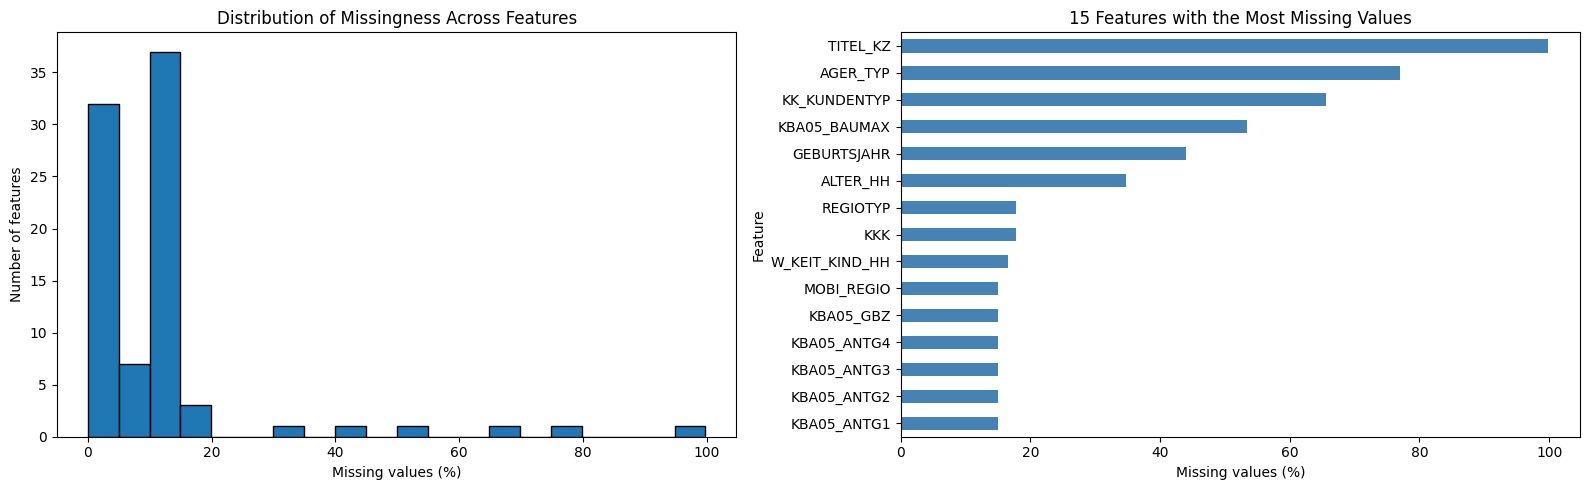

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Each observation in this histogram represents one feature.
axes[0].hist(
    column_missing['missing_percent'],
    bins=20,
    edgecolor='black'
)
axes[0].set_title('Distribution of Missingness Across Features')
axes[0].set_xlabel('Missing values (%)')
axes[0].set_ylabel('Number of features')

# Show the 15 features with the highest missing percentages.
column_missing.head(15)['missing_percent'].sort_values().plot.barh(
    ax=axes[1],
    color='steelblue'
)
axes[1].set_title('15 Features with the Most Missing Values')
axes[1].set_xlabel('Missing values (%)')
axes[1].set_ylabel('Feature')

plt.tight_layout()
plt.show()

In [9]:
# Investigate patterns in the amount of missing data in each column.
# Compare missingness row by row for selected feature pairs.
feature_pairs = [
    ('VERS_TYP', 'SHOPPER_TYP'),
    ('VERS_TYP', 'HEALTH_TYP'),
    ('LP_FAMILIE_FEIN', 'LP_FAMILIE_GROB'),
    ('CAMEO_DEUG_2015', 'CAMEO_DEU_2015'),
    ('CAMEO_DEU_2015', 'CAMEO_INTL_2015')
]

pattern_results = []

for feature_a, feature_b in feature_pairs:
    missing_a = azdias[feature_a].isna()
    missing_b = azdias[feature_b].isna()

    pattern_results.append({
        'feature_a': feature_a,
        'feature_b': feature_b,
        'both_missing': (missing_a & missing_b).sum(),
        'different_missing_status': (missing_a != missing_b).sum()
    })

display(pd.DataFrame(pattern_results))


,feature_a,feature_b,both_missing,different_missing_status
0,VERS_TYP,SHOPPER_TYP,111196,0
1,VERS_TYP,HEALTH_TYP,111196,0
2,LP_FAMILIE_FEIN,LP_FAMILIE_GROB,77792,0
3,CAMEO_DEUG_2015,CAMEO_DEU_2015,99352,0
4,CAMEO_DEU_2015,CAMEO_INTL_2015,99352,0


In [10]:
# Remove the outlier columns from the dataset. (You'll perform other data
# engineering tasks such as re-encoding and imputation later.)
# Choose a threshold within the observed gap in missingness.
column_missing_threshold = 30

# Save the selected column names for the cleaning function later.
columns_to_drop = column_missing.index[
    column_missing['missing_percent'] > column_missing_threshold
].tolist()

print("Columns removed:", columns_to_drop)

# Remove the columns without removing any rows.
azdias = azdias.drop(columns=columns_to_drop)

print(f"Remaining shape: {azdias.shape}")



Columns removed: ['TITEL_KZ', 'AGER_TYP', 'KK_KUNDENTYP', 'KBA05_BAUMAX', 'GEBURTSJAHR', 'ALTER_HH']
Remaining shape: (891221, 79)


#### Discussion 1.1.2: Assess Missing Data in Each Column

After converting the documented missing and unknown codes to NaN, most features had between 0% and 17.74% missing values. Six features stood apart, with missingness ranging from 34.81% to 99.76%. I selected a 30% threshold within this gap and removed TITEL_KZ (99.76%), AGER_TYP (76.96%), KK_KUNDENTYP (65.60%), KBA05_BAUMAX (53.47%), GEBURTSJAHR (44.02%), and ALTER_HH (34.81%). This reduced the dataset from 85 to 79 features without removing any rows and avoided extensive imputation for these highly incomplete columns.
Missing values also showed shared patterns across several features. Row-level comparisons confirmed identical missingness patterns for VERS_TYP and SHOPPER_TYP, VERS_TYP and HEALTH_TYP, LP_FAMILIE_FEIN and LP_FAMILIE_GROB, and all three CAMEO features. 
These patterns suggest that some information may be unavailable together because of shared data sources or collection processes, although the cause cannot be established from this analysis alone.

#### Step 1.1.3: Assess Missing Data in Each Row

Now, you'll perform a similar assessment for the rows of the dataset. How much data is missing in each row? As with the columns, you should see some groups of points that have a very different numbers of missing values. Divide the data into two subsets: one for data points that are above some threshold for missing values, and a second subset for points below that threshold.

In order to know what to do with the outlier rows, we should see if the distribution of data values on columns that are not missing data (or are missing very little data) are similar or different between the two groups. Select at least five of these columns and compare the distribution of values.
- You can use seaborn's [`countplot()`](https://seaborn.pydata.org/generated/seaborn.countplot.html) function to create a bar chart of code frequencies and matplotlib's [`subplot()`](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.subplot.html) function to put bar charts for the two subplots side by side.
- To reduce repeated code, you might want to write a function that can perform this comparison, taking as one of its arguments a column to be compared.

Depending on what you observe in your comparison, this will have implications on how you approach your conclusions later in the analysis. If the distributions of non-missing features look similar between the data with many missing values and the data with few or no missing values, then we could argue that simply dropping those points from the analysis won't present a major issue. On the other hand, if the data with many missing values looks very different from the data with few or no missing values, then we should make a note on those data as special. We'll revisit these data later on. **Either way, you should continue your analysis for now using just the subset of the data with few or no missing values.**

count    891221.000000
mean          5.649894
std          13.234687
min           0.000000
25%           0.000000
50%           0.000000
75%           3.000000
max          49.000000
dtype: float64

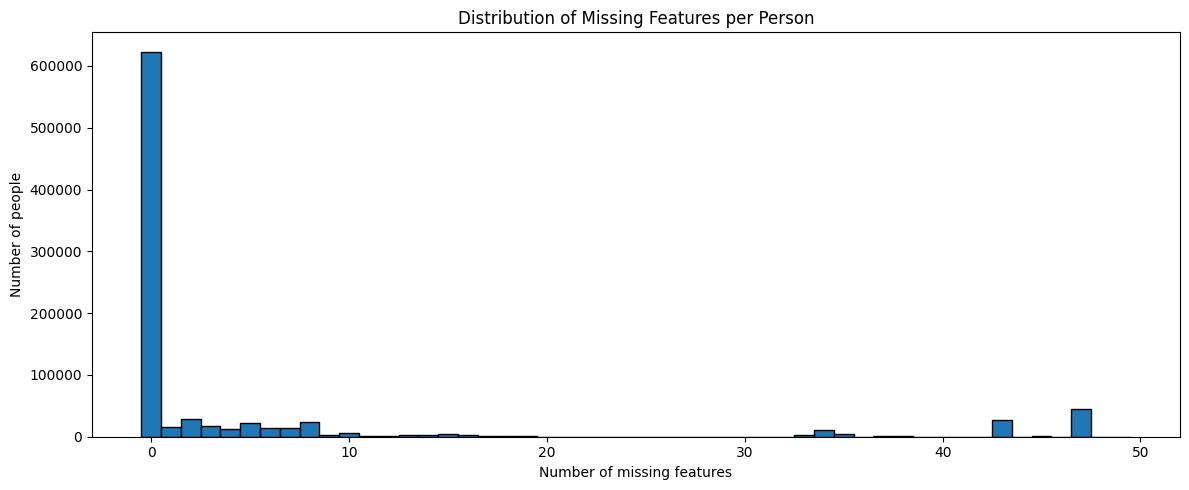

In [11]:
# How much data is missing in each row of the dataset?
# Count missing features for each person.
row_missing = azdias.isna().sum(axis=1)

display(row_missing.describe())

# Use one bin for each possible integer count.
plt.figure(figsize=(12, 5))
plt.hist(
    row_missing,
    bins=np.arange(row_missing.max() + 2) - 0.5,
    edgecolor='black'
)
plt.title('Distribution of Missing Features per Person')
plt.xlabel('Number of missing features')
plt.ylabel('Number of people')
plt.tight_layout()
plt.show()



In [12]:
# Write code to divide the data into two subsets based on the number of missing
# values in each row.

# Apply the threshold after removing the six outlier columns.
row_missing_threshold = 10

low_missing_mask = row_missing <= row_missing_threshold

azdias_low_missing = azdias.loc[low_missing_mask].copy()
azdias_high_missing = azdias.loc[~low_missing_mask].copy()

# Save counts for the final population/customer comparison.
population_total_count = len(azdias)
population_high_missing_count = len(azdias_high_missing)

subset_summary = pd.DataFrame({
    'rows': [
        len(azdias_low_missing),
        len(azdias_high_missing)
    ],
    'percent_of_population': [
        low_missing_mask.mean() * 100,
        (~low_missing_mask).mean() * 100
    ]
}, index=['Low missingness (≤10)', 'High missingness (>10)'])

display(subset_summary.round(2))


,rows,percent_of_population
Low missingness (≤10),780153,87.54
High missingness (>10),111068,12.46


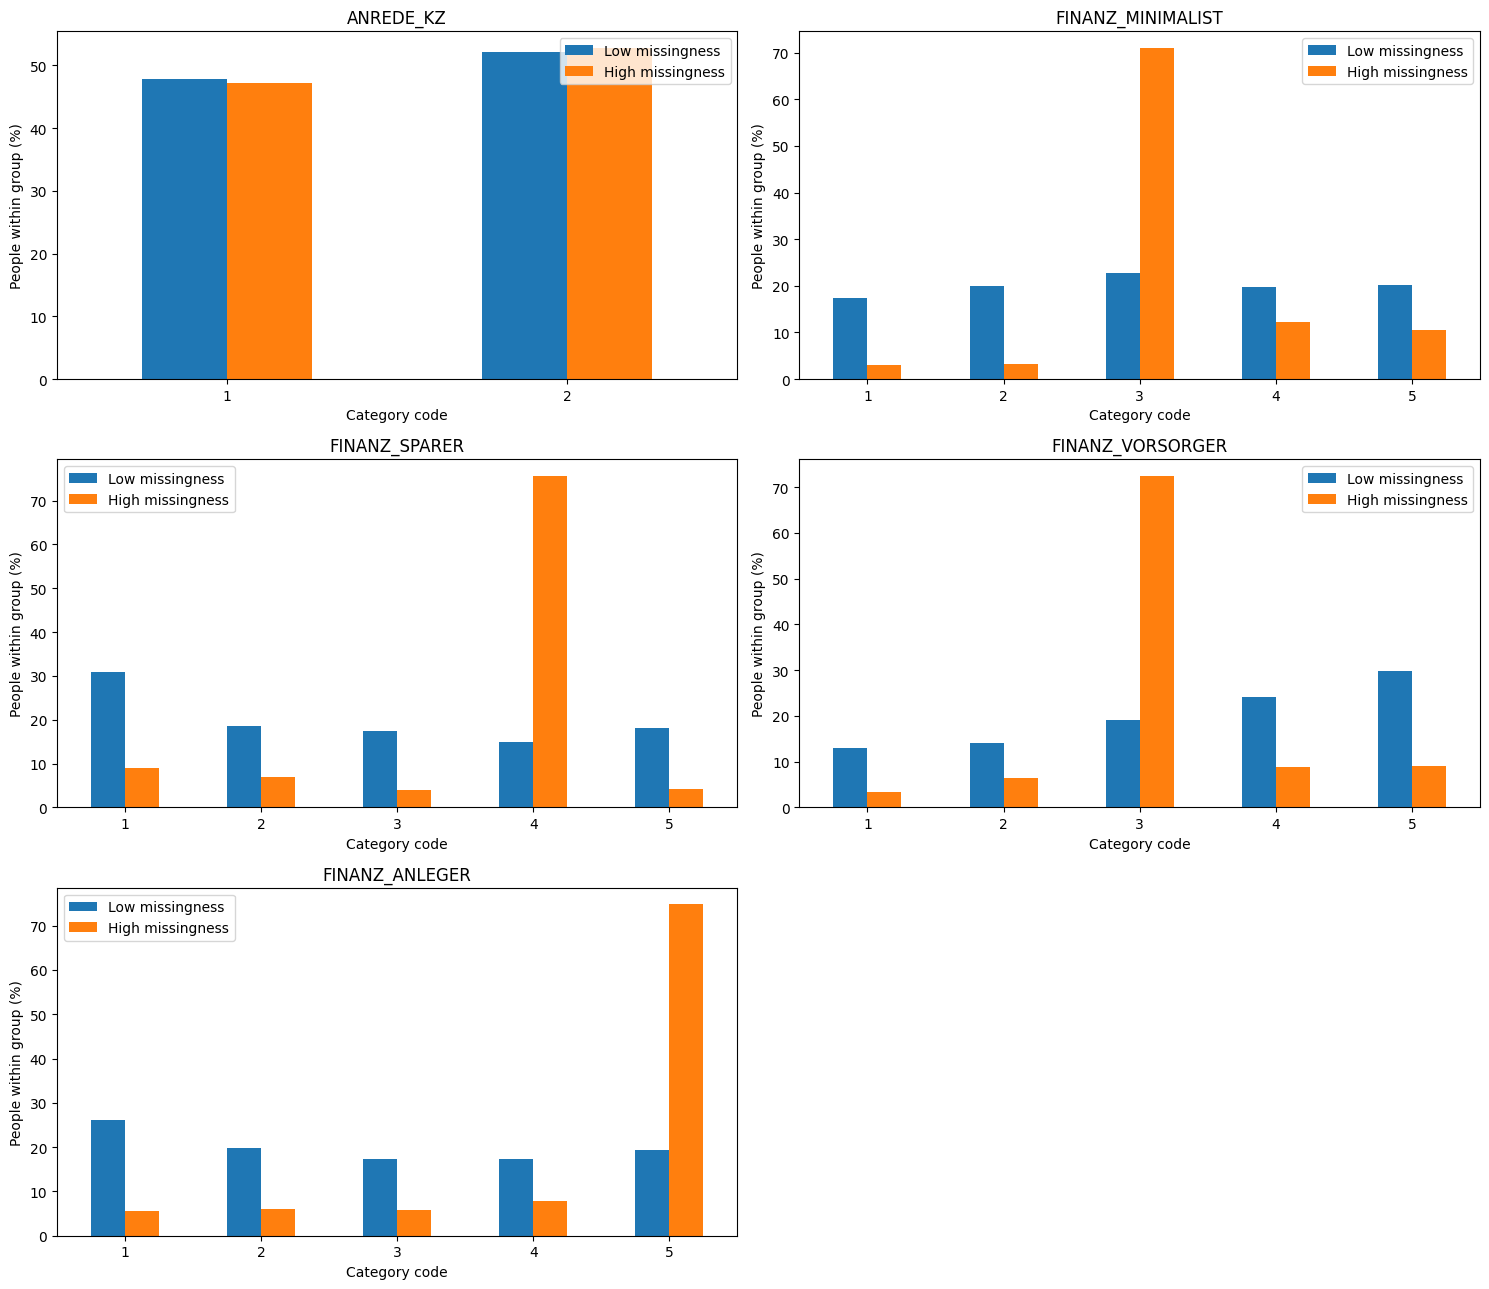

In [13]:
# Compare the distribution of values for at least five columns where there are
# no or few missing values, between the two subsets.
comparison_features = [
    'ANREDE_KZ',
    'FINANZ_MINIMALIST',
    'FINANZ_SPARER',
    'FINANZ_VORSORGER',
    'FINANZ_ANLEGER'
]


def compare_subset_distributions(column, low_df, high_df, ax):
    """Compare observed category percentages in two subsets."""
    distributions = pd.concat(
        [
            low_df[column].value_counts(normalize=True).rename('Low missingness'),
            high_df[column].value_counts(normalize=True).rename('High missingness')
        ],
        axis=1
    ).fillna(0).sort_index() * 100

    distributions.plot.bar(ax=ax, rot=0)

    ax.set_title(column)
    ax.set_xlabel('Category code')
    ax.set_ylabel('People within group (%)')

    return distributions


fig, axes = plt.subplots(3, 2, figsize=(15, 13))
comparison_tables = {}

for column, ax in zip(comparison_features, axes.flat):
    comparison_tables[column] = compare_subset_distributions(
        column,
        azdias_low_missing,
        azdias_high_missing,
        ax
    )

# Hide the unused sixth subplot.
axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()


In [14]:
for column, table in comparison_tables.items():
    table = table.copy()

    table['High minus low (percentage points)'] = (
        table['High missingness'] - table['Low missingness']
    )

    print(column)
    display(table.round(2))

ANREDE_KZ


,Low missingness,High missingness,High minus low (percentage points)
ANREDE_KZ,,,
1,47.88,47.18,-0.69
2,52.12,52.82,0.69


FINANZ_MINIMALIST


,Low missingness,High missingness,High minus low (percentage points)
FINANZ_MINIMALIST,,,
1,17.48,2.93,-14.55
2,19.97,3.20,-16.77
3,22.73,71.10,48.37
4,19.68,12.26,-7.42
5,20.15,10.51,-9.64


FINANZ_SPARER


,Low missingness,High missingness,High minus low (percentage points)
FINANZ_SPARER,,,
1,30.78,9.04,-21.74
2,18.61,7.05,-11.57
3,17.42,4.02,-13.40
4,15.03,75.63,60.60
5,18.16,4.26,-13.90


FINANZ_VORSORGER


,Low missingness,High missingness,High minus low (percentage points)
FINANZ_VORSORGER,,,
1,12.88,3.47,-9.42
2,14.03,6.35,-7.68
3,19.15,72.44,53.29
4,24.17,8.73,-15.44
5,29.77,9.02,-20.75


FINANZ_ANLEGER


,Low missingness,High missingness,High minus low (percentage points)
FINANZ_ANLEGER,,,
1,26.22,5.60,-20.63
2,19.83,5.92,-13.91
3,17.24,5.88,-11.36
4,17.30,7.78,-9.51
5,19.41,74.82,55.41


#### Discussion 1.1.3: Assess Missing Data in Each Row

After removing the six highly incomplete columns, the median number of missing features per person was zero, and the 75th percentile was three. The histogram showed a large concentration of relatively complete records and separate groups with substantially more missing information. I divided the data into a low-missingness subset with at most 10 missing features and a high-missingness subset with more than 10.
I compared within-group category percentages for five features without missing values: ANREDE_KZ, FINANZ_MINIMALIST, FINANZ_SPARER, FINANZ_VORSORGER, and FINANZ_ANLEGER. ANREDE_KZ had similar distributions, with differences below one percentage point. However, all four financial features differed substantially. For example, FINANZ_SPARER category 4 represented 75.63% of the high-missingness group versus 15.03% of the low-missingness group. FINANZ_ANLEGER category 5 represented 74.82% versus 19.41%, respectively.
The high-missingness group therefore differs systematically on the observed financial features. Excluding these records may introduce selection bias, so the resulting demographic clusters should primarily be interpreted as describing the retained population. I will continue modeling with the low-missingness subset and account for the excluded records as a separate high-missingness group in the final population/customer comparison.

### Step 1.2: Select and Re-Encode Features

Checking for missing data isn't the only way in which you can prepare a dataset for analysis. Since the unsupervised learning techniques to be used will only work on data that is encoded numerically, you need to make a few encoding changes or additional assumptions to be able to make progress. In addition, while almost all of the values in the dataset are encoded using numbers, not all of them represent numeric values. Check the third column of the feature summary (`feat_info`) for a summary of types of measurement.
- For numeric and interval data, these features can be kept without changes.
- Most of the variables in the dataset are ordinal in nature. While ordinal values may technically be non-linear in spacing, make the simplifying assumption that the ordinal variables can be treated as being interval in nature (that is, kept without any changes).
- Special handling may be necessary for the remaining two variable types: categorical, and 'mixed'.

In the first two parts of this sub-step, you will perform an investigation of the categorical and mixed-type features and make a decision on each of them, whether you will keep, drop, or re-encode each. Then, in the last part, you will create a new data frame with only the selected and engineered columns.

Data wrangling is often the trickiest part of the data analysis process, and there's a lot of it to be done here. But stick with it: once you're done with this step, you'll be ready to get to the machine learning parts of the project!

In [15]:
# How many features are there of each data type?
# Keep metadata for the 79 features remaining after column removal.
retained_feat_info = feat_info.loc[
    feat_info['attribute'].isin(azdias_low_missing.columns)
].copy()

display(retained_feat_info['type'].value_counts())



type
ordinal        49
categorical    18
mixed           6
numeric         6
Name: count, dtype: int64

#### Step 1.2.1: Re-Encode Categorical Features

For categorical data, you would ordinarily need to encode the levels as dummy variables. Depending on the number of categories, perform one of the following:
- For binary (two-level) categoricals that take numeric values, you can keep them without needing to do anything.
- There is one binary variable that takes on non-numeric values. For this one, you need to re-encode the values as numbers or create a dummy variable.
- For multi-level categoricals (three or more values), you can choose to encode the values using multiple dummy variables (e.g. via [OneHotEncoder](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)), or (to keep things straightforward) just drop them from the analysis. As always, document your choices in the Discussion section.

In [16]:
# Assess categorical variables: which are binary, which are multi-level, and
# which one needs to be re-encoded?
categorical_columns = retained_feat_info.loc[
    retained_feat_info['type'] == 'categorical',
    'attribute'
].tolist()

categorical_summary = pd.DataFrame({
    'unique_non_missing_values': [
        azdias_low_missing[column].nunique()
        for column in categorical_columns
    ],
    'observed_values': [
        sorted(azdias_low_missing[column].dropna().unique().tolist())
        for column in categorical_columns
    ],
    'pandas_dtype': [
        str(azdias_low_missing[column].dtype)
        for column in categorical_columns
    ]
}, index=categorical_columns)

display(categorical_summary)



,unique_non_missing_values,observed_values,pandas_dtype
ANREDE_KZ,2,"[1, 2]",int64
CJT_GESAMTTYP,6,"[1.0, 2.0, 3.0, 4.0, 5.0, 6.0]",float64
FINANZTYP,6,"[1, 2, 3, 4, 5, 6]",int64
GFK_URLAUBERTYP,12,"[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...",float64
GREEN_AVANTGARDE,2,"[0, 1]",int64
LP_FAMILIE_FEIN,11,"[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...",float64
LP_FAMILIE_GROB,5,"[1.0, 2.0, 3.0, 4.0, 5.0]",float64
LP_STATUS_FEIN,10,"[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ...",float64
LP_STATUS_GROB,5,"[1.0, 2.0, 3.0, 4.0, 5.0]",float64
NATIONALITAET_KZ,3,"[1.0, 2.0, 3.0]",float64


In [17]:
# Re-encode categorical variable(s) to be kept in the analysis.
# Identify categorical features with two observed categories.
binary_categorical_columns = categorical_summary.index[
    categorical_summary['unique_non_missing_values'] == 2
].tolist()

# Save the multi-level categorical columns to remove.
multi_level_categorical_columns = categorical_summary.index[
    categorical_summary['unique_non_missing_values'] > 2
].tolist()

# Create our working feature-selection dataframe.
azdias_selected = azdias_low_missing.drop(
    columns=multi_level_categorical_columns
).copy()

# Encode east/west: O = Ost (East), W = West.
# Existing NaNs remain NaN.
azdias_selected['OST_WEST_KZ'] = (
    azdias_selected['OST_WEST_KZ'].map({'O': 0, 'W': 1})
)

print("Binary categorical features retained:")
print(binary_categorical_columns)

print("\nMulti-level categorical features removed:")
print(multi_level_categorical_columns)

print("\nShape after categorical processing:", azdias_selected.shape)

display(azdias_selected[binary_categorical_columns].head())


Binary categorical features retained:
['ANREDE_KZ', 'GREEN_AVANTGARDE', 'SOHO_KZ', 'VERS_TYP', 'OST_WEST_KZ']

Multi-level categorical features removed:
['CJT_GESAMTTYP', 'FINANZTYP', 'GFK_URLAUBERTYP', 'LP_FAMILIE_FEIN', 'LP_FAMILIE_GROB', 'LP_STATUS_FEIN', 'LP_STATUS_GROB', 'NATIONALITAET_KZ', 'SHOPPER_TYP', 'ZABEOTYP', 'GEBAEUDETYP', 'CAMEO_DEUG_2015', 'CAMEO_DEU_2015']

Shape after categorical processing: (780153, 66)


#### Discussion 1.2.1: Re-Encode Categorical Features

Of the 18 categorical features remaining after missing-data filtering, five were binary and 13 had more than two categories. I retained ANREDE_KZ, SOHO_KZ, and VERS_TYP in their existing numeric encodings. I converted OST_WEST_KZ from text to numeric values using O = 0 and W = 1, preserving missing values.
I initially retained GREEN_AVANTGARDE, but a subsequent redundancy check showed that it exactly duplicated the engineered YOUTH_AVANTGARDE feature wherever both were observed and across all retained rows after imputation. I therefore removed GREEN_AVANTGARDE and retained YOUTH_AVANTGARDE to avoid giving the same characteristic extra weight in PCA and clustering.
I removed the 13 multi-level categorical features: CJT_GESAMTTYP, FINANZTYP, GFK_URLAUBERTYP, LP_FAMILIE_FEIN, LP_FAMILIE_GROB, LP_STATUS_FEIN, LP_STATUS_GROB, NATIONALITAET_KZ, SHOPPER_TYP, ZABEOTYP, GEBAEUDETYP, CAMEO_DEUG_2015, and CAMEO_DEU_2015. Their category codes should not be treated as continuous quantities because doing so would impose artificial ordering and distances.
Dropping these features is permitted by the project instructions and limits dimensionality and preprocessing complexity. However, it also discards potentially useful demographic information. One-hot encoding would be an alternative for retaining that information.

#### Step 1.2.2: Engineer Mixed-Type Features

There are a handful of features that are marked as "mixed" in the feature summary that require special treatment in order to be included in the analysis. There are two in particular that deserve attention; the handling of the rest are up to your own choices:
- "PRAEGENDE_JUGENDJAHRE" combines information on three dimensions: generation by decade, movement (mainstream vs. avantgarde), and nation (east vs. west). While there aren't enough levels to disentangle east from west, you should create two new variables to capture the other two dimensions: an interval-type variable for decade, and a binary variable for movement.
- "CAMEO_INTL_2015" combines information on two axes: wealth and life stage. Break up the two-digit codes by their 'tens'-place and 'ones'-place digits into two new ordinal variables (which, for the purposes of this project, is equivalent to just treating them as their raw numeric values).
- If you decide to keep or engineer new features around the other mixed-type features, make sure you note your steps in the Discussion section.

Be sure to check `Data_Dictionary.md` for the details needed to finish these tasks.

In [18]:
# Identify the mixed-type features still in our working dataframe.
mixed_columns = retained_feat_info.loc[
    retained_feat_info['type'] == 'mixed',
    'attribute'
].tolist()

display(
    retained_feat_info.loc[
        retained_feat_info['type'] == 'mixed'
    ]
)

for column in mixed_columns:
    print(f"\n{column}")
    print(azdias_selected[column].value_counts(dropna=False).head(15))


LP_LEBENSPHASE_FEIN
LP_LEBENSPHASE_FEIN
1.0     58136
5.0     52159
NaN     46574
6.0     42948
2.0     36884
8.0     28617
7.0     24851
29.0    24691
13.0    24497
11.0    24043
10.0    22827
31.0    22177
12.0    21387
30.0    20821
15.0    18834
Name: count, dtype: int64

LP_LEBENSPHASE_GROB
LP_LEBENSPHASE_GROB
2.0     148575
1.0     129823
3.0     105026
12.0     68616
4.0      50539
9.0      45512
5.0      45456
NaN      43894
10.0     37845
11.0     30476
8.0      27029
6.0      26617
7.0      20745
Name: count, dtype: int64

PRAEGENDE_JUGENDJAHRE
PRAEGENDE_JUGENDJAHRE
14.0    178410
8.0     138678
10.0     83881
5.0      83645
3.0      53098
15.0     41029
11.0     34642
9.0      33197
NaN      26474
6.0      25517
12.0     24034
4.0      20343
1.0      20242
2.0       7438
13.0      5561
Name: count, dtype: int64

WOHNLAGE
WOHNLAGE
3.0    246155
7.0    167130
4.0    134022
2.0     98784
5.0     72899
1.0     43191
8.0     15018
0.0      2954
Name: count, dtype: int64

CAMEO_I

In [19]:
from pathlib import Path
import re

# Read the feature definitions provided with the project.
dictionary_lines = Path('Data_Dictionary.md').read_text(
    encoding='utf-8'
).splitlines()

for column in mixed_columns:
    print(f"\n{'=' * 60}\n{column}\n{'=' * 60}")

    # Find the Markdown heading containing this feature's name.
    matching_headings = [
        i
        for i, line in enumerate(dictionary_lines)
        if re.match(r'^#{1,6}\s+', line)
        and re.search(rf'\b{re.escape(column)}\b', line)
    ]

    if not matching_headings:
        print("Heading not found. Locate this feature manually in Data_Dictionary.md.")
        continue

    start = matching_headings[0]

    # Stop at the next Markdown heading.
    end = next(
        (
            i
            for i in range(start + 1, len(dictionary_lines))
            if re.match(r'^#{1,6}\s+', dictionary_lines[i])
        ),
        len(dictionary_lines)
    )

    print('\n'.join(dictionary_lines[start:end]))

In [20]:
# Investigate "PRAEGENDE_JUGENDJAHRE" and engineer two new variables.
# Map the original codes to the decade they describe.
youth_decade_map = {
    1: 1940, 2: 1940,
    3: 1950, 4: 1950,
    5: 1960, 6: 1960, 7: 1960,
    8: 1970, 9: 1970,
    10: 1980, 11: 1980, 12: 1980, 13: 1980,
    14: 1990, 15: 1990
}

# 0 = mainstream; 1 = avantgarde.
youth_movement_map = {
    1: 0, 2: 1,
    3: 0, 4: 1,
    5: 0, 6: 1, 7: 1,
    8: 0, 9: 1,
    10: 0, 11: 1, 12: 0, 13: 1,
    14: 0, 15: 1
}

azdias_selected['YOUTH_DECADE'] = (
    azdias_selected['PRAEGENDE_JUGENDJAHRE'].map(youth_decade_map)
)

azdias_selected['YOUTH_AVANTGARDE'] = (
    azdias_selected['PRAEGENDE_JUGENDJAHRE'].map(youth_movement_map)
)

# Confirm every observed original code was mapped.
observed_youth = azdias_selected['PRAEGENDE_JUGENDJAHRE'].notna()

assert azdias_selected.loc[
    observed_youth, ['YOUTH_DECADE', 'YOUTH_AVANTGARDE']
].notna().all().all()

display(
    azdias_selected[
        ['PRAEGENDE_JUGENDJAHRE', 'YOUTH_DECADE', 'YOUTH_AVANTGARDE']
    ].head(10)
)


In [21]:
# Investigate "CAMEO_INTL_2015" and engineer two new variables.

# Convert string codes such as "24" into numeric values.
# Unexpected nonnumeric values raise an error rather than being hidden.
cameo_numeric = pd.to_numeric(
    azdias_selected['CAMEO_INTL_2015'],
    errors='raise'
)

# Split the two-digit code.
azdias_selected['CAMEO_WEALTH'] = cameo_numeric // 10
azdias_selected['CAMEO_LIFE_STAGE'] = cameo_numeric % 10

# Validate the ranges of the engineered features.
assert azdias_selected['CAMEO_WEALTH'].dropna().isin(
    [1, 2, 3, 4, 5]
).all()

assert azdias_selected['CAMEO_LIFE_STAGE'].dropna().isin(
    [1, 2, 3, 4, 5]
).all()

display(
    azdias_selected[
        ['CAMEO_INTL_2015', 'CAMEO_WEALTH', 'CAMEO_LIFE_STAGE']
    ].head(10)
)

#### Discussion 1.2.2: Engineer Mixed-Type Features

First I split PRAEGENDE_JUGENDJAHRE into YOUTH_DECADE, representing the formative decade from the 1940s through the 1990s, and YOUTH_AVANTGARDE, coded as 0 for mainstream and 1 for avantgarde. This separates two dimensions that cannot be represented meaningfully by the original category numbers. The missing values were preserved. I did not derive an east/west youth feature because several codes combine both regions.

Then I split CAMEO_INTL_2015 into CAMEO_WEALTH using the tens digit and CAMEO_LIFE_STAGE using the ones digit. Wealth codes run from 1 for wealthy households to 5 for poorer households. Life-stage codes run from 1 for pre-family couples and singles to 5 for elders in retirement. Following the project instructions, these ordered categories will be treated as approximately interval-scaled.

I chose to exclude the remaining four mixed features. LP_LEBENSPHASE_FEIN and LP_LEBENSPHASE_GROB combine household structure, income, and age in category labels without a single numeric ordering. WOHNLAGE mixes neighborhood quality with rural flags and a no-score category. PLZ8_BAUMAX mixes residential building-size categories with a business-building category. Dropping these features avoids imposing inappropriate numeric distances, although it sacrifices information that further engineering or categorical encoding could retain.
All six original mixed-type columns were removed during final feature selection, leaving the four engineered features in their place.

#### Step 1.2.3: Complete Feature Selection

In order to finish this step up, you need to make sure that your data frame now only has the columns that you want to keep. To summarize, the dataframe should consist of the following:
- All numeric, interval, and ordinal type columns from the original dataset.
- Binary categorical features (all numerically-encoded).
- Engineered features from other multi-level categorical features and mixed features.

Make sure that for any new columns that you have engineered, that you've excluded the original columns from the final dataset. Otherwise, their values will interfere with the analysis later on the project. For example, you should not keep "PRAEGENDE_JUGENDJAHRE", since its values won't be useful for the algorithm: only the values derived from it in the engineered features you created should be retained. As a reminder, your data should only be from **the subset with few or no missing values**.

In [22]:
# If there are other re-engineering tasks you need to perform, make sure you
# take care of them here. (Dealing with missing data will come in step 2.1.)

# Remove original mixed features and the redundant movement feature.
redundant_columns = ['GREEN_AVANTGARDE']

azdias_selected = azdias_selected.drop(
    columns=mixed_columns + redundant_columns,
    errors='ignore'
)



In [23]:
# Do whatever you need to in order to ensure that the dataframe only contains
# the columns that should be passed to the algorithm functions.

# Verify that all retained features are numeric.
non_numeric_columns = azdias_selected.select_dtypes(
    exclude='number'
).columns.tolist()

print("Final shape:", azdias_selected.shape)
print("Non-numeric columns:", non_numeric_columns)
print(
    "Remaining missing values:",
    f"{azdias_selected.isna().sum().sum():,}"
)

assert not non_numeric_columns
assert not azdias_selected.columns.duplicated().any()

# Preserve feature names and order for later customer processing.
selected_feature_columns = azdias_selected.columns.tolist()



Final shape: (780153, 63)
Non-numeric columns: []
Remaining missing values: 529,094


### Step 1.3: Create a Cleaning Function

Even though you've finished cleaning up the general population demographics data, it's important to look ahead to the future and realize that you'll need to perform the same cleaning steps on the customer demographics data. In this substep, complete the function below to execute the main feature selection, encoding, and re-engineering steps you performed above. Then, when it comes to looking at the customer data in Step 3, you can just run this function on that DataFrame to get the trimmed dataset in a single step.

In [24]:
def clean_data(df):
    """
    Apply the established demographic cleaning rules.

    Input:
        DataFrame containing the original demographic features.
        The six high-missingness columns may already be removed.

    Output:
        Numeric DataFrame containing retained rows and the selected
        features, in the established column order.
        Remaining NaNs are preserved for later imputation.

    Uses the cleaning decisions and mappings defined above.
    """

    # Select the 79 original features used to assess row missingness.
    # This also removes the six high-missingness columns, if present.
    required_columns = retained_feat_info['attribute'].tolist()

    missing_columns = [
        column for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(f"Required columns are missing: {missing_columns}")

    cleaned = df.loc[:, required_columns].copy()

    # Convert documented missing-value codes to NaN.
    for column in required_columns:
        codes = missing_code_map[column]

        if codes:
            cleaned[column] = cleaned[column].replace(codes, np.nan)

    # Apply the same row threshold before further feature selection.
    missing_per_row = cleaned.isna().sum(axis=1)

    cleaned = cleaned.loc[
        missing_per_row <= row_missing_threshold
    ].copy()

    # Remove the same multi-level categorical features.
    cleaned = cleaned.drop(columns=multi_level_categorical_columns)

    # Encode the binary east/west feature.
    cleaned['OST_WEST_KZ'] = cleaned['OST_WEST_KZ'].map({
        'O': 0,
        'W': 1
    })

    # Engineer youth decade and movement.
    youth = cleaned['PRAEGENDE_JUGENDJAHRE']

    cleaned['YOUTH_DECADE'] = youth.map(youth_decade_map)
    cleaned['YOUTH_AVANTGARDE'] = youth.map(youth_movement_map)

    # Check that all observed youth codes were mapped.
    observed_youth = youth.notna()

    if cleaned.loc[
        observed_youth, ['YOUTH_DECADE', 'YOUTH_AVANTGARDE']
    ].isna().any().any():
        raise ValueError("An unexpected youth code could not be mapped.")

    # Engineer CAMEO wealth and life stage.
    cameo = pd.to_numeric(
        cleaned['CAMEO_INTL_2015'],
        errors='raise'
    )

    cleaned['CAMEO_WEALTH'] = cameo // 10
    cleaned['CAMEO_LIFE_STAGE'] = cameo % 10

    for column in ['CAMEO_WEALTH', 'CAMEO_LIFE_STAGE']:
        if not cleaned[column].dropna().isin([1, 2, 3, 4, 5]).all():
            raise ValueError(f"Unexpected category in {column}.")

    # Remove original mixed features and the redundant movement feature.
    cleaned = cleaned.drop(
        columns=mixed_columns + redundant_columns
    )

    # Enforce the same feature names and order for both datasets.
    cleaned = cleaned.loc[:, selected_feature_columns]

    if len(cleaned.select_dtypes(exclude='number').columns) > 0:
        raise ValueError("Nonnumeric features remain after cleaning.")

    return cleaned
    

In [25]:
# azdias still contains all people and the 79 retained original features.
# Its missing codes have already been converted; repeating that operation
# leaves existing NaNs unchanged.
azdias_clean = clean_data(azdias)

# Compare the function's result with our step-by-step result.
pd.testing.assert_frame_equal(
    azdias_clean,
    azdias_selected,
    check_dtype=False
)

# Verify that row filtering also matches.
assert azdias_clean.index.equals(azdias_low_missing.index)

print("Cleaning function reproduces the step-by-step result.")
print("Cleaned shape:", azdias_clean.shape)
print(
    "Remaining missing values:",
    f"{azdias_clean.isna().sum().sum():,}"
)
print(
    "People excluded for high missingness:",
    f"{len(azdias) - len(azdias_clean):,}"
)

Cleaning function reproduces the step-by-step result.
Cleaned shape: (780153, 63)
Remaining missing values: 529,094
People excluded for high missingness: 111,068


## Step 2: Feature Transformation

### Step 2.1: Apply Feature Scaling

Before we apply dimensionality reduction techniques to the data, we need to perform feature scaling so that the principal component vectors are not influenced by the natural differences in scale for features. Starting from this part of the project, you'll want to keep an eye on the [API reference page for sklearn](http://scikit-learn.org/stable/modules/classes.html) to help you navigate to all of the classes and functions that you'll need. In this substep, you'll need to check the following:

- sklearn requires that data not have missing values in order for its estimators to work properly. So, before applying the scaler to your data, make sure that you've cleaned the DataFrame of the remaining missing values. This can be as simple as just removing all data points with missing data, or applying an [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html) to replace all missing values. You might also try a more complicated procedure where you temporarily remove missing values in order to compute the scaling parameters before re-introducing those missing values and applying imputation. Think about how much missing data you have and what possible effects each approach might have on your analysis, and justify your decision in the discussion section below.
- For the actual scaling function, a [StandardScaler](http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) instance is suggested, scaling each feature to mean 0 and standard deviation 1.
- For these classes, you can make use of the `.fit_transform()` method to both fit a procedure to the data as well as apply the transformation to the data at the same time. Don't forget to keep the fit sklearn objects handy, since you'll be applying them to the customer demographics data towards the end of the project.

In [26]:
# If you've not yet cleaned the dataset of all NaN values, then investigate and
# do that now.

from sklearn.impute import SimpleImputer

# Inspect which retained features still have missing values.
remaining_missing_pct = (
    azdias_clean.isna().mean() * 100
).sort_values(ascending=False)

display(
    remaining_missing_pct[remaining_missing_pct > 0]
    .rename('missing_percent')
    .round(2)
)

# Ensure no feature is entirely missing.
assert not azdias_clean.isna().all().any()

# Learn each column's most frequent value from the general population.
imputer = SimpleImputer(strategy='most_frequent')

azdias_imputed = imputer.fit_transform(azdias_clean)

print("Imputed shape:", azdias_imputed.shape)
print("Missing values after imputation:", np.isnan(azdias_imputed).sum())

assert azdias_imputed.shape == azdias_clean.shape
assert np.isfinite(azdias_imputed).all()



W_KEIT_KIND_HH          7.21
KKK                     7.02
REGIOTYP                7.02
VERS_TYP                4.43
HEALTH_TYP              4.43
YOUTH_AVANTGARDE        3.39
YOUTH_DECADE            3.39
KBA05_ANTG1             3.13
KBA05_ANTG2             3.13
KBA05_ANTG3             3.13
KBA05_ANTG4             3.13
KBA05_GBZ               3.13
MOBI_REGIO              3.13
PLZ8_ANTG1              1.04
PLZ8_ANTG3              1.04
PLZ8_ANTG2              1.04
PLZ8_ANTG4              1.04
PLZ8_HHZ                1.04
PLZ8_GBZ                1.04
ANZ_HAUSHALTE_AKTIV     0.74
KBA13_ANZAHL_PKW        0.73
ARBEIT                  0.51
RELAT_AB                0.51
ORTSGR_KLS9             0.50
ONLINE_AFFINITAET       0.49
RETOURTYP_BK_S          0.49
CAMEO_WEALTH            0.47
CAMEO_LIFE_STAGE        0.47
ANZ_HH_TITEL            0.41
ALTERSKATEGORIE_GROB    0.34
INNENSTADT              0.07
EWDICHTE                0.07
BALLRAUM                0.07
KONSUMNAEHE             0.01
GEBAEUDETYP_RA

Imputed shape: (780153, 63)
Missing values after imputation: 0


In [27]:
# Apply feature scaling to the general population demographics data.

from sklearn.preprocessing import StandardScaler

# Learn the population means and standard deviations, then scale.
scaler = StandardScaler()

azdias_scaled = scaler.fit_transform(azdias_imputed)

# Check the result.
scaling_summary = pd.DataFrame({
    'mean_after_scaling': azdias_scaled.mean(axis=0),
    'std_after_scaling': azdias_scaled.std(axis=0)
}, index=selected_feature_columns)

display(scaling_summary.round(6))

print("Scaled shape:", azdias_scaled.shape)
print("All values finite:", np.isfinite(azdias_scaled).all())

# Constant columns remain zero after scaling.
constant_features = scaling_summary.index[
    scaler.var_ == 0
].tolist()

print("Constant features:", constant_features)

assert np.isfinite(azdias_scaled).all()
assert np.allclose(azdias_scaled.mean(axis=0), 0, atol=1e-8)

nonconstant_mask = scaler.var_ > 0

assert np.allclose(
    azdias_scaled.std(axis=0)[nonconstant_mask],
    1,
    atol=1e-8
)




,mean_after_scaling,std_after_scaling
ALTERSKATEGORIE_GROB,-0.0,1.0
ANREDE_KZ,0.0,1.0
FINANZ_MINIMALIST,0.0,1.0
FINANZ_SPARER,0.0,1.0
FINANZ_VORSORGER,0.0,1.0
FINANZ_ANLEGER,0.0,1.0
FINANZ_UNAUFFAELLIGER,0.0,1.0
FINANZ_HAUSBAUER,-0.0,1.0
HEALTH_TYP,-0.0,1.0
RETOURTYP_BK_S,0.0,1.0


Scaled shape: (780153, 63)
All values finite: True
Constant features: []


### Discussion 2.1: Apply Feature Scaling

The cleaned dataset contained 529,094 missing entries, approximately 1.08% of its cells. Missingness varied by feature: W_KEIT_KIND_HH had the highest remaining percentage at 7.21%, followed by KKK and REGIOTYP at 7.02% each.
I decided to use SimpleImputer with the most_frequent strategy to fill missing entries with each feature's most common observed value. In this way it preserves valid codes for the many ordinal and binary features and avoids removing additional people. However, it increases the frequency of common values and may reduce variability or alter relationships between features. After imputation, no missing values remained.
I then applied StandardScaler to give every feature approximately zero mean and unit variance. This prevents differences in measurement scale from dominating PCA and the distances used by k-means. All 63 features had nonzero variance, and the transformed dataset contained only finite values.
Both the imputer and scaler were fitted on the retained general-population data. Their fitted transformations will later be applied to customers without refitting, ensuring that both datasets use the same replacement values and scaling parameters.

### Step 2.2: Perform Dimensionality Reduction

On your scaled data, you are now ready to apply dimensionality reduction techniques.

- Use sklearn's [PCA](http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) class to apply principal component analysis on the data, thus finding the vectors of maximal variance in the data. To start, you should not set any parameters (so all components are computed) or set a number of components that is at least half the number of features (so there's enough features to see the general trend in variability).
- Check out the ratio of variance explained by each principal component as well as the cumulative variance explained. Try plotting the cumulative or sequential values using matplotlib's [`plot()`](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.plot.html) function. Based on what you find, select a value for the number of transformed features you'll retain for the clustering part of the project.
- Once you've made a choice for the number of components to keep, make sure you re-fit a PCA instance to perform the decided-on transformation.

In [28]:
# Apply PCA to the data.
from sklearn.decomposition import PCA

# Fit all components to inspect the complete variance distribution.

pca_full = PCA(svd_solver='full')
pca_full.fit(azdias_scaled)

print("Number of components fitted:", pca_full.n_components_)



Number of components fitted: 63


,component,explained_variance_percent,cumulative_variance_percent
0,1,16.85,16.85
1,2,13.56,30.41
2,3,9.59,40.00
3,4,4.65,44.65
4,5,3.79,48.44
5,6,3.23,51.67
6,7,2.87,54.54
7,8,2.55,57.09
8,9,2.41,59.50
9,10,2.14,61.63


80% variance requires 22 components
85% variance requires 27 components
90% variance requires 34 components
95% variance requires 44 components


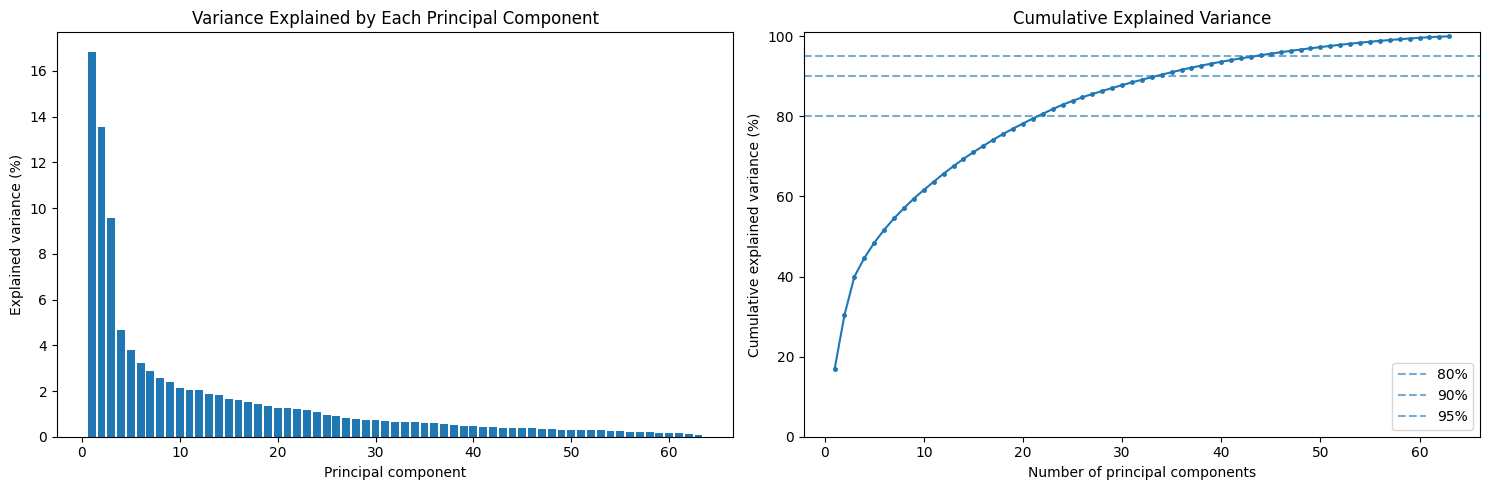

In [29]:
# Investigate the variance accounted for by each principal component.

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

component_numbers = np.arange(1, len(explained_variance) + 1)

variance_summary = pd.DataFrame({
    'component': component_numbers,
    'explained_variance_percent': explained_variance * 100,
    'cumulative_variance_percent': cumulative_variance * 100
})

display(variance_summary.round(2))

# Compare component counts for several possible retention targets.
for target in [0.80, 0.85, 0.90, 0.95]:
    required_components = np.searchsorted(
        cumulative_variance, target
    ) + 1

    print(
        f"{target:.0%} variance requires "
        f"{required_components} components"
    )

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(component_numbers, explained_variance * 100)
axes[0].set_title('Variance Explained by Each Principal Component')
axes[0].set_xlabel('Principal component')
axes[0].set_ylabel('Explained variance (%)')

axes[1].plot(
    component_numbers,
    cumulative_variance * 100,
    marker='.',
    markersize=5
)

for target in [80, 90, 95]:
    axes[1].axhline(
        target,
        linestyle='--',
        alpha=0.6,
        label=f'{target}%'
    )

axes[1].set_title('Cumulative Explained Variance')
axes[1].set_xlabel('Number of principal components')
axes[1].set_ylabel('Cumulative explained variance (%)')
axes[1].set_ylim(0, 101)
axes[1].legend()

plt.tight_layout()
plt.show()


In [30]:
# Re-apply PCA to the data while selecting for number of components to retain.
# Retain the smallest number of components reaching 90% variance.
n_components = 34

pca = PCA(
    n_components=n_components,
    svd_solver='full'
)

azdias_pca = pca.fit_transform(azdias_scaled)

print("Original shape:", azdias_scaled.shape)
print("PCA-transformed shape:", azdias_pca.shape)
print(
    "Variance retained:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

assert azdias_pca.shape == (len(azdias_clean), n_components)
assert np.isfinite(azdias_pca).all()


Original shape: (780153, 63)
PCA-transformed shape: (780153, 34)
Variance retained: 90.43%


### Discussion 2.2: Perform Dimensionality Reduction

I initially fitted PCA with all 63 components to examine individual and cumulative explained variance. The first component explained 16.85%, the second 13.56%, and the third 9.59%, totaling approximately 40.00%. Later components made progressively smaller contributions, with no single sharp cutoff that captured most of the variance.

The analysis showed that 22 components were needed to retain at least 80% of the variance, 27 for 85%, 34 for 90%, and 44 for 95%. I selected 34 components, retaining 90.43% of the variance while reducing dimensionality from 63 to 34 features, approximately 46%. Reaching 95% would require ten additional components, retaining 95.28% in total: about 4.85 percentage points more variance.

I refitted PCA with 34 components and transformed the retained general-population data for clustering. This balances dimensionality reduction with preservation of variation, although explained variance alone does not establish which representation will produce the best clusters.


### Step 2.3: Interpret Principal Components

Now that we have our transformed principal components, it's a nice idea to check out the weight of each variable on the first few components to see if they can be interpreted in some fashion.

As a reminder, each principal component is a unit vector that points in the direction of highest variance (after accounting for the variance captured by earlier principal components). The further a weight is from zero, the more the principal component is in the direction of the corresponding feature. If two features have large weights of the same sign (both positive or both negative), then increases in one tend expect to be associated with increases in the other. To contrast, features with different signs can be expected to show a negative correlation: increases in one variable should result in a decrease in the other.

- To investigate the features, you should map each weight to their corresponding feature name, then sort the features according to weight. The most interesting features for each principal component, then, will be those at the beginning and end of the sorted list. Use the data dictionary document to help you understand these most prominent features, their relationships, and what a positive or negative value on the principal component might indicate.
- You should investigate and interpret feature associations from the first three principal components in this substep. To help facilitate this, you should write a function that you can call at any time to print the sorted list of feature weights, for the *i*-th principal component. This might come in handy in the next step of the project, when you interpret the tendencies of the discovered clusters.

In [31]:
# Map weights for the first principal component to corresponding feature names
# and then print the linked values, sorted by weight.
# HINT: Try defining a function here or in a new cell that you can reuse in the
# other cells.

def component_weights(pca_model, feature_names, component_number):
    """Return sorted feature weights, using component numbers starting at 1."""
    weights = pd.Series(
        pca_model.components_[component_number - 1],
        index=feature_names,
        name=f'PC{component_number}_weight'
    ).sort_values()

    print(
        f"PC{component_number} explained variance: "
        f"{pca_model.explained_variance_ratio_[component_number - 1]:.2%}"
    )

    display(pd.concat([
        weights.head(8).to_frame().assign(end='Most negative'),
        weights.tail(8).to_frame().assign(end='Most positive')
    ]))

    return weights


pc1_weights = component_weights(pca, selected_feature_columns, 1)



PC1 explained variance: 16.85%


,PC1_weight,end
MOBI_REGIO,-0.229245,Most negative
PLZ8_ANTG1,-0.227196,Most negative
FINANZ_MINIMALIST,-0.221729,Most negative
KBA05_ANTG1,-0.216420,Most negative
KBA05_GBZ,-0.216066,Most negative
KONSUMNAEHE,-0.169969,Most negative
INNENSTADT,-0.167898,Most negative
PLZ8_GBZ,-0.167376,Most negative
PLZ8_ANTG2,0.155671,Most positive
FINANZ_HAUSBAUER,0.159274,Most positive


In [32]:
# Map weights for the second principal component to corresponding feature names
# and then print the linked values, sorted by weight.
pc2_weights = component_weights(pca, selected_feature_columns, 2)



PC2 explained variance: 13.56%


,PC2_weight,end
SEMIO_REL,-0.254132,Most negative
YOUTH_DECADE,-0.238783,Most negative
FINANZ_SPARER,-0.231505,Most negative
SEMIO_TRADV,-0.228229,Most negative
SEMIO_PFLICHT,-0.226774,Most negative
FINANZ_UNAUFFAELLIGER,-0.224619,Most negative
SEMIO_KULT,-0.219985,Most negative
FINANZ_ANLEGER,-0.203848,Most negative
SEMIO_KAEM,0.115363,Most positive
SEMIO_KRIT,0.118370,Most positive


In [33]:
# Map weights for the third principal component to corresponding feature names
# and then print the linked values, sorted by weight.

pc3_weights = component_weights(pca, selected_feature_columns, 3)

PC3 explained variance: 9.59%


,PC3_weight,end
ANREDE_KZ,-0.369326,Most negative
SEMIO_KAEM,-0.338178,Most negative
SEMIO_DOM,-0.315646,Most negative
SEMIO_KRIT,-0.274075,Most negative
SEMIO_RAT,-0.219075,Most negative
FINANZ_ANLEGER,-0.189206,Most negative
SEMIO_ERL,-0.173796,Most negative
YOUTH_DECADE,-0.112447,Most negative
W_KEIT_KIND_HH,0.085748,Most positive
FINANZ_VORSORGER,0.102368,Most positive


In [34]:
# Read the dictionary again so this cell can run independently
# of our earlier dictionary inspection.
from pathlib import Path
import re

dictionary_lines = Path('Data_Dictionary.md').read_text(
    encoding='utf-8'
).splitlines()

# Prefixes also capture headings that group related features together.
heading_keywords = [
    'ANREDE_KZ',
    'ALTERSKATEGORIE_GROB',
    'FINANZ',
    'HH_EINKOMMEN_SCORE',
    'PLZ8_ANTG',
    'EWDICHTE',
    'ORTSGR_KLS9',
    'SEMIO'
]

heading_positions = [
    i for i, line in enumerate(dictionary_lines)
    if re.match(r'^#{1,6}\s+', line)
]

for position, start in enumerate(heading_positions):
    heading = dictionary_lines[start]

    if any(keyword in heading for keyword in heading_keywords):
        end = (
            heading_positions[position + 1]
            if position + 1 < len(heading_positions)
            else len(dictionary_lines)
        )

        print('\n' + '=' * 60)
        print('\n'.join(dictionary_lines[start:end]))

### Discussion 2.3: Interpret Principal Components

I examined the strongest positive and negative feature weights for the first three principal components, which together explained 40.00% of the variance. The interpretations use the data dictionary because several scales run in reverse: higher FINANZ and SEMIO codes indicate weaker affinity, while higher household-income and CAMEO wealth codes indicate lower income or affluence.

PC1 explained 16.85% of the variance and combines residential environment with economic position. Positive weights for PLZ8_ANTG3, PLZ8_ANTG4, EWDICHTE, and ORTSGR_KLS9 associate higher scores with larger residential buildings, greater household density, and larger communities. Negative weights for PLZ8_ANTG1 and KBA05_ANTG1 contrast this with areas containing more small residential buildings. Positive weights for HH_EINKOMMEN_SCORE and CAMEO_WEALTH associate the higher-scoring end with lower income and affluence. This component therefore describes a combined residential and economic gradient rather than a pure wealth measure.

PC2 explained 13.56% of the variance and primarily reflects age/generation together with lifestyle and financial classifications. ALTERSKATEGORIE_GROB has a positive weight, while YOUTH_DECADE has a negative weight, associating higher scores with older age groups and earlier formative decades. Negative weights for SEMIO_REL, SEMIO_TRADV, SEMIO_PFLICHT, and FINANZ_SPARER associate this end with stronger religious, traditional, dutiful, and saving affinities. Positive weights for SEMIO_ERL, SEMIO_LUST, and FINANZ_VORSORGER associate the opposite, younger end with stronger event-oriented, sensual, and preparedness affinities.

PC3 explained 9.59% of the variance and captures gender-associated patterns in the provider's personality classifications. ANREDE_KZ has a strong negative weight; since 1 represents male and 2 female, higher component scores tend toward male coding. Negative weights for SEMIO_KAEM, SEMIO_DOM, SEMIO_KRIT, and SEMIO_RAT associate that end with stronger combative, dominant, critical, and rational affinities. Positive weights for SEMIO_VERT, SEMIO_SOZ, SEMIO_FAM, and SEMIO_KULT associate the lower-scoring end with female coding and stronger dreamful, social, family, and cultural affinities. These are dataset-specific associations, not universal gender characteristics.

Component signs are arbitrary: reversing all weights would reverse the score direction without changing the underlying axis. The interpretations describe associations along each component and do not establish causation or every pairwise correlation.

## Step 3: Clustering

### Step 3.1: Apply Clustering to General Population

You've assessed and cleaned the demographics data, then scaled and transformed them. Now, it's time to see how the data clusters in the principal components space. In this substep, you will apply k-means clustering to the dataset and use the average within-cluster distances from each point to their assigned cluster's centroid to decide on a number of clusters to keep.

- Use sklearn's [KMeans](http://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html#sklearn.cluster.KMeans) class to perform k-means clustering on the PCA-transformed data.
- Then, compute the average difference from each point to its assigned cluster's center. **Hint**: The KMeans object's `.score()` method might be useful here, but note that in sklearn, scores tend to be defined so that larger is better. Try applying it to a small, toy dataset, or use an internet search to help your understanding.
- Perform the above two steps for a number of different cluster counts. You can then see how the average distance decreases with an increasing number of clusters. However, each additional cluster provides a smaller net benefit. Use this fact to select a final number of clusters in which to group the data. **Warning**: because of the large size of the dataset, it can take a long time for the algorithm to resolve. The more clusters to fit, the longer the algorithm will take. You should test for cluster counts through at least 10 clusters to get the full picture, but you shouldn't need to test for a number of clusters above about 30.
- Once you've selected a final number of clusters to use, re-fit a KMeans instance to perform the clustering operation. Make sure that you also obtain the cluster assignments for the general demographics data, since you'll be using them in the final Step 3.3.

In [35]:
# Over a number of different cluster counts...


    # run k-means clustering on the data and...
    
    
    # compute the average within-cluster distances.
    
from sklearn.cluster import KMeans

# Use the same reproducible population sample for every candidate k.
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(azdias_pca),
    size=min(100_000, len(azdias_pca)),
    replace=False
)

clustering_sample = azdias_pca[sample_indices]

cluster_counts = [2, 4, 6, 8, 10, 12, 15, 20]
clustering_results = []

for k in cluster_counts:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(clustering_sample)

    # Euclidean distance from each point to its assigned centroid.
    assigned_centers = model.cluster_centers_[labels]

    distances = np.linalg.norm(
        clustering_sample - assigned_centers,
        axis=1
    )

    clustering_results.append({
        'n_clusters': k,
        'mean_distance': distances.mean(),
        'mean_squared_distance': (
            model.inertia_ / len(clustering_sample)
        )
    })

    print(
        f"k={k:2d} | "
        f"Mean distance={distances.mean():.4f}",
        flush=True
    )

clustering_results = pd.DataFrame(clustering_results)

display(clustering_results.round(4))
    
    

k= 2 | Mean distance=6.8358
k= 4 | Mean distance=6.3319
k= 6 | Mean distance=6.0440
k= 8 | Mean distance=5.8343
k=10 | Mean distance=5.7461
k=12 | Mean distance=5.6804
k=15 | Mean distance=5.5570
k=20 | Mean distance=5.4162


,n_clusters,mean_distance,mean_squared_distance
0,2,6.8358,48.9829
1,4,6.3319,42.2652
2,6,6.0440,38.8425
3,8,5.8343,36.3449
4,10,5.7461,35.2573
5,12,5.6804,34.0210
6,15,5.5570,32.6841
7,20,5.4162,30.3516


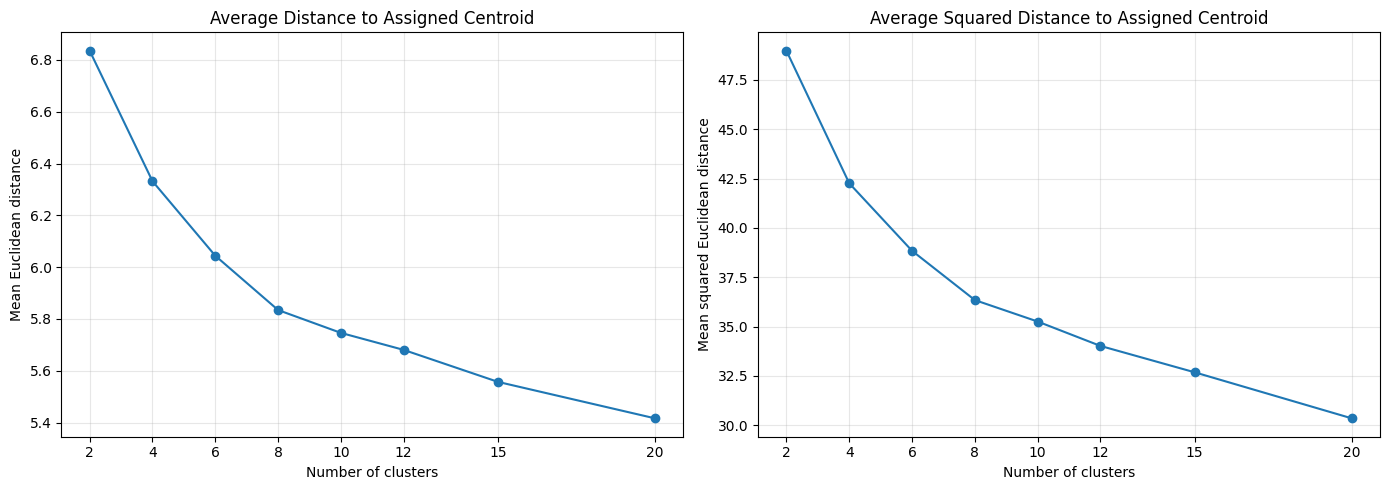

In [36]:
# Investigate the change in within-cluster distance across number of clusters.
# HINT: Use matplotlib's plot function to visualize this relationship.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, title, ylabel in [
    (
        axes[0],
        'mean_distance',
        'Average Distance to Assigned Centroid',
        'Mean Euclidean distance'
    ),
    (
        axes[1],
        'mean_squared_distance',
        'Average Squared Distance to Assigned Centroid',
        'Mean squared Euclidean distance'
    )
]:
    ax.plot(
        clustering_results['n_clusters'],
        clustering_results[metric],
        marker='o'
    )
    ax.set_title(title)
    ax.set_xlabel('Number of clusters')
    ax.set_ylabel(ylabel)
    ax.set_xticks(cluster_counts)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



In [37]:
# Re-fit the k-means model with the selected number of clusters and obtain
# cluster predictions for the general population demographics data.
# Fit the selected model on all retained population records.
n_clusters = 8

kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=42,
    n_init=10
)

population_labels = kmeans.fit_predict(azdias_pca)

# Preserve row identities alongside cluster assignments.
population_clusters = pd.Series(
    population_labels,
    index=azdias_clean.index,
    name='cluster'
)

# Summarize the resulting cluster sizes.
population_cluster_summary = (
    population_clusters.value_counts()
    .sort_index()
    .rename('people')
    .to_frame()
)

population_cluster_summary['percent_of_retained_population'] = (
    population_cluster_summary['people']
    / len(population_clusters)
    * 100
)

display(population_cluster_summary.round(2))

print("People clustered:", f"{len(population_clusters):,}")
print("Clusters found:", population_clusters.nunique())
print(
    "Mean squared distance:",
    f"{kmeans.inertia_ / len(azdias_pca):.4f}"
)
print("Iterations:", kmeans.n_iter_)

assert len(population_clusters) == len(azdias_clean)
assert population_clusters.nunique() == n_clusters



,people,percent_of_retained_population
cluster,,
0,68391,8.77
1,89069,11.42
2,130370,16.71
3,84238,10.80
4,103561,13.27
5,128012,16.41
6,106486,13.65
7,70026,8.98


People clustered: 780,153
Clusters found: 8
Mean squared distance: 36.3979
Iterations: 18


### Discussion 3.1: Apply Clustering to General Population

I evaluated k-means with 2, 4, 6, 8, 10, 12, 15, and 20 clusters using a fixed random sample of 100,000 retained general-population records in the 34-component PCA space. Every candidate used the same sample, random_state=42, and 10 initializations. I reported both the mean Euclidean distance to the assigned centroid and the mean squared distance, since k-means optimizes squared distances.

Both curves showed diminishing improvements, with a bend around 6–8 clusters rather than a uniquely sharp elbow. The mean Euclidean distance decreased from 6.0440 at six clusters to 5.8343 at eight, an improvement of approximately 0.1049 per added cluster. Increasing from eight to ten reduced it to 5.7461, approximately 0.0441 per added cluster. The mean squared distance similarly decreased from 38.8425 to 36.3449 and then 35.2573. Beyond this region, distance improvements were generally smaller per additional cluster.

I selected eight clusters as a practical balance between within-cluster compactness and interpretable segmentation. This is a justified modeling choice rather than proof of eight natural demographic groups. I then fitted the final eight-cluster model on all 780,153 retained general-population records, obtaining a mean squared distance of 36.3979 after 18 iterations, and saved their assignments. The same fitted model was used to assign customers to these population-defined segments.


### Step 3.2: Apply All Steps to the Customer Data

Now that you have clusters and cluster centers for the general population, it's time to see how the customer data maps on to those clusters. Take care to not confuse this for re-fitting all of the models to the customer data. Instead, you're going to use the fits from the general population to clean, transform, and cluster the customer data. In the last step of the project, you will interpret how the general population fits apply to the customer data.

- Don't forget when loading in the customers data, that it is semicolon (`;`) delimited.
- Apply the same feature wrangling, selection, and engineering steps to the customer demographics using the `clean_data()` function you created earlier. (You can assume that the customer demographics data has similar meaning behind missing data patterns as the general demographics data.)
- Use the sklearn objects from the general demographics data, and apply their transformations to the customers data. That is, you should not be using a `.fit()` or `.fit_transform()` method to re-fit the old objects, nor should you be creating new sklearn objects! Carry the data through the feature scaling, PCA, and clustering steps, obtaining cluster assignments for all of the data in the customer demographics data.

In [38]:
# Load the customer demographics using the same delimiter.
customers = pd.read_csv(
    'Udacity_CUSTOMERS_Subset.csv',
    sep=';'
)

print(
    f"Customers: {customers.shape[0]:,} rows "
    f"and {customers.shape[1]} columns"
)

Customers: 191,652 rows and 85 columns


In [39]:
# Apply preprocessing, feature transformation, and clustering from the general
# demographics onto the customer data, obtaining cluster predictions for the
# customer demographics data.

# Apply the same cleaning rules and row-missingness threshold.
customers_clean = clean_data(customers)

# Save exclusion counts for the final comparison.
customer_total_count = len(customers)
customer_high_missing_count = (
    customer_total_count - len(customers_clean)
)

# Confirm identical features and ordering.
assert customers_clean.columns.equals(azdias_clean.columns)

# Reuse the fitted population imputer, scaler, and PCA.
customers_imputed = imputer.transform(customers_clean)
customers_scaled = scaler.transform(customers_imputed)
customers_pca = pca.transform(customers_scaled)

# Assign customers to the existing population cluster centers.
customer_labels = kmeans.predict(customers_pca)

customer_clusters = pd.Series(
    customer_labels,
    index=customers_clean.index,
    name='cluster'
)

# Validate the transformed data and assignments.
assert customers_imputed.shape == customers_clean.shape
assert customers_pca.shape == (len(customers_clean), n_components)
assert np.isfinite(customers_pca).all()
assert len(customer_clusters) == len(customers_clean)

print("Cleaned customer shape:", customers_clean.shape)
print("Missing values after imputation:", np.isnan(customers_imputed).sum())
print("PCA-transformed customer shape:", customers_pca.shape)
print("Customers assigned to clusters:", f"{len(customer_clusters):,}")
print(
    "Customers excluded for high missingness:",
    f"{customer_high_missing_count:,}"
)



Cleaned customer shape: (139068, 63)
Missing values after imputation: 0
PCA-transformed customer shape: (139068, 34)
Customers assigned to clusters: 139,068
Customers excluded for high missingness: 52,584


### Step 3.3: Compare Customer Data to Demographics Data

At this point, you have clustered data based on demographics of the general population of Germany, and seen how the customer data for a mail-order sales company maps onto those demographic clusters. In this final substep, you will compare the two cluster distributions to see where the strongest customer base for the company is.

Consider the proportion of persons in each cluster for the general population, and the proportions for the customers. If we think the company's customer base to be universal, then the cluster assignment proportions should be fairly similar between the two. If there are only particular segments of the population that are interested in the company's products, then we should see a mismatch from one to the other. If there is a higher proportion of persons in a cluster for the customer data compared to the general population (e.g. 5% of persons are assigned to a cluster for the general population, but 15% of the customer data is closest to that cluster's centroid) then that suggests the people in that cluster to be a target audience for the company. On the other hand, the proportion of the data in a cluster being larger in the general population than the customer data (e.g. only 2% of customers closest to a population centroid that captures 6% of the data) suggests that group of persons to be outside of the target demographics.

Take a look at the following points in this step:

- Compute the proportion of data points in each cluster for the general population and the customer data. Visualizations will be useful here: both for the individual dataset proportions, but also to visualize the ratios in cluster representation between groups. Seaborn's [`countplot()`](https://seaborn.pydata.org/generated/seaborn.countplot.html) or [`barplot()`](https://seaborn.pydata.org/generated/seaborn.barplot.html) function could be handy.
  - Recall the analysis you performed in step 1.1.3 of the project, where you separated out certain data points from the dataset if they had more than a specified threshold of missing values. If you found that this group was qualitatively different from the main bulk of the data, you should treat this as an additional data cluster in this analysis. Make sure that you account for the number of data points in this subset, for both the general population and customer datasets, when making your computations!
- Which cluster or clusters are overrepresented in the customer dataset compared to the general population? Select at least one such cluster and infer what kind of people might be represented by that cluster. Use the principal component interpretations from step 2.3 or look at additional components to help you make this inference. Alternatively, you can use the `.inverse_transform()` method of the PCA and StandardScaler objects to transform centroids back to the original data space and interpret the retrieved values directly.
- Perform a similar investigation for the underrepresented clusters. Which cluster or clusters are underrepresented in the customer dataset compared to the general population, and what kinds of people are typified by these clusters?

In [40]:
# Compare the proportion of data in each cluster for the customer data to the
# proportion of data in each cluster for the general population.
# Count assignments, including clusters with zero customers.
population_counts = (
    population_clusters.value_counts()
    .reindex(range(n_clusters), fill_value=0)
)

customer_counts = (
    customer_clusters.value_counts()
    .reindex(range(n_clusters), fill_value=0)
)

cluster_comparison = pd.DataFrame({
    'population_count': population_counts,
    'customer_count': customer_counts
})

cluster_comparison.index.name = 'cluster'

# Compare distributions among people retained for clustering.
cluster_comparison['population_retained_pct'] = (
    population_counts / len(population_clusters) * 100
)

cluster_comparison['customer_retained_pct'] = (
    customer_counts / len(customer_clusters) * 100
)

cluster_comparison['difference_pp'] = (
    cluster_comparison['customer_retained_pct']
    - cluster_comparison['population_retained_pct']
)

cluster_comparison['representation_ratio'] = (
    cluster_comparison['customer_retained_pct']
    / cluster_comparison['population_retained_pct']
)

display(cluster_comparison.round(3))



,population_count,customer_count,population_retained_pct,customer_retained_pct,difference_pp,representation_ratio
cluster,,,,,,
0,68391,1406,8.766,1.011,-7.755,0.115
1,89069,2625,11.417,1.888,-9.529,0.165
2,130370,69590,16.711,50.040,33.329,2.994
3,84238,1528,10.798,1.099,-9.699,0.102
4,103561,18291,13.274,13.153,-0.122,0.991
5,128012,26686,16.409,19.189,2.781,1.169
6,106486,15076,13.649,10.841,-2.809,0.794
7,70026,3866,8.976,2.780,-6.196,0.310


In [41]:
# Include excluded records so each dataset's percentages total 100%.
all_records_comparison = pd.DataFrame({
    'population_count': population_counts.to_numpy(),
    'customer_count': customer_counts.to_numpy()
}, index=[f'Cluster {i}' for i in range(n_clusters)])

all_records_comparison.loc['High missingness'] = [
    population_high_missing_count,
    customer_high_missing_count
]

all_records_comparison['population_all_pct'] = (
    all_records_comparison['population_count']
    / population_total_count * 100
)

all_records_comparison['customer_all_pct'] = (
    all_records_comparison['customer_count']
    / customer_total_count * 100
)

assert all_records_comparison['population_count'].sum() == population_total_count
assert all_records_comparison['customer_count'].sum() == customer_total_count

display(all_records_comparison.round(2))

,population_count,customer_count,population_all_pct,customer_all_pct
Cluster 0,68391,1406,7.67,0.73
Cluster 1,89069,2625,9.99,1.37
Cluster 2,130370,69590,14.63,36.31
Cluster 3,84238,1528,9.45,0.80
Cluster 4,103561,18291,11.62,9.54
Cluster 5,128012,26686,14.36,13.92
Cluster 6,106486,15076,11.95,7.87
Cluster 7,70026,3866,7.86,2.02
High missingness,111068,52584,12.46,27.44


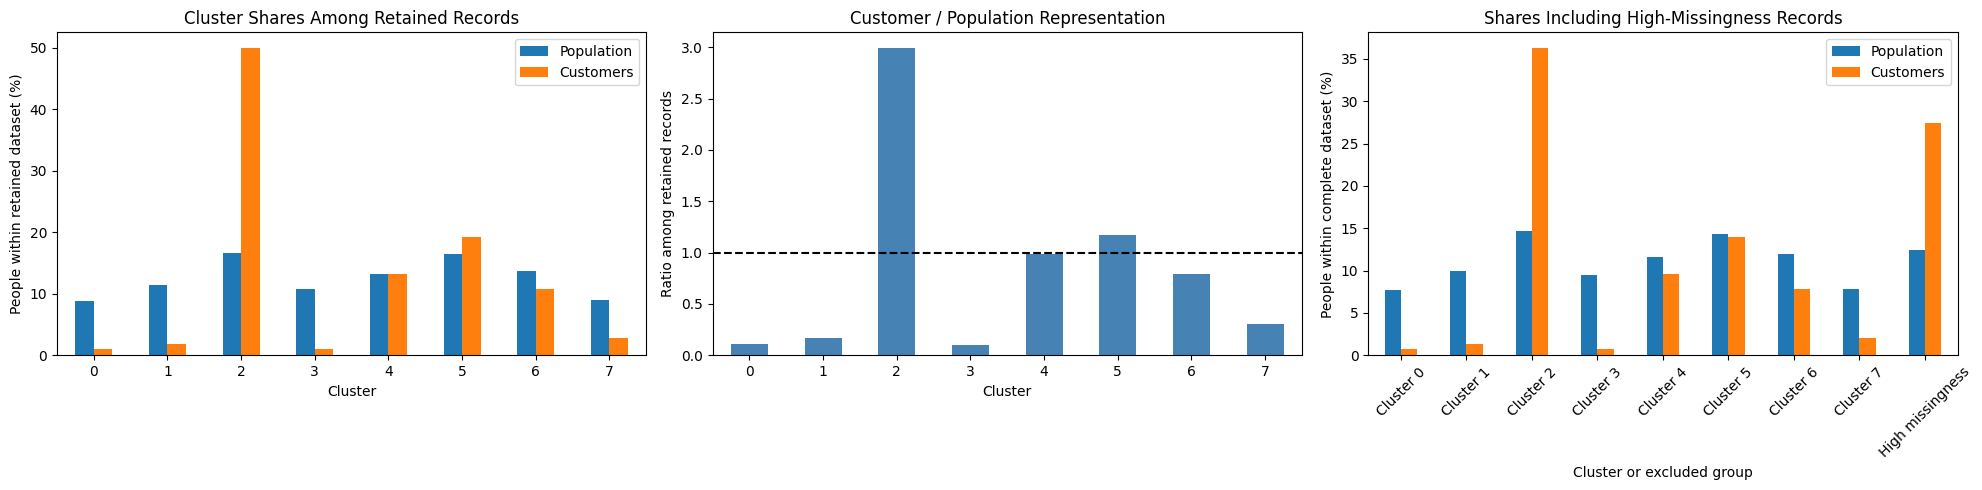

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

cluster_comparison[
    ['population_retained_pct', 'customer_retained_pct']
].rename(columns={
    'population_retained_pct': 'Population',
    'customer_retained_pct': 'Customers'
}).plot.bar(ax=axes[0], rot=0)

axes[0].set_title('Cluster Shares Among Retained Records')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('People within retained dataset (%)')

cluster_comparison['representation_ratio'].plot.bar(
    ax=axes[1],
    rot=0,
    color='steelblue'
)

axes[1].axhline(1, color='black', linestyle='--')
axes[1].set_title('Customer / Population Representation')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Ratio among retained records')

all_records_comparison[
    ['population_all_pct', 'customer_all_pct']
].rename(columns={
    'population_all_pct': 'Population',
    'customer_all_pct': 'Customers'
}).plot.bar(ax=axes[2], rot=45)

axes[2].set_title('Shares Including High-Missingness Records')
axes[2].set_xlabel('Cluster or excluded group')
axes[2].set_ylabel('People within complete dataset (%)')

plt.tight_layout()
plt.show()

In [43]:
# What kinds of people are part of a cluster that is overrepresented in the
# customer data compared to the general population?
# Select the most overrepresented cluster among retained records.
overrepresented_cluster = int(
    cluster_comparison['representation_ratio'].idxmax()
)

underrepresented_cluster = int(
    cluster_comparison['representation_ratio'].idxmin()
)

# Recover approximate cluster centroids in scaled feature space.
centroids_scaled = pd.DataFrame(
    pca.inverse_transform(kmeans.cluster_centers_),
    index=pd.Index(range(n_clusters), name='cluster'),
    columns=selected_feature_columns
)

# Recover approximate centroids in original feature units.
centroids_original = pd.DataFrame(
    scaler.inverse_transform(centroids_scaled.to_numpy()),
    index=centroids_scaled.index,
    columns=selected_feature_columns
)


def inspect_cluster(cluster_id):
    """Show PCA coordinates and the largest reconstructed feature deviations."""
    print(f"Cluster {cluster_id}")
    print(
        "Representation ratio:",
        f"{cluster_comparison.loc[cluster_id, 'representation_ratio']:.3f}"
    )

    # Coordinates connect the cluster to our first three PC interpretations.
    display(pd.Series(
        kmeans.cluster_centers_[cluster_id, :3],
        index=['PC1', 'PC2', 'PC3'],
        name='centroid_coordinate'
    ).to_frame().round(3))

    # Rank features by distance from the population mean in scaled units.
    deviations = centroids_scaled.loc[cluster_id]

    strongest_features = (
        deviations.abs()
        .sort_values(ascending=False)
        .head(12)
        .index
    )

    profile = pd.DataFrame({
        'approx_scaled_deviation': deviations.loc[strongest_features],
        'approx_original_centroid': (
            centroids_original.loc[cluster_id, strongest_features]
        ),
        'population_imputed_mean': pd.Series(
            scaler.mean_,
            index=selected_feature_columns
        ).loc[strongest_features]
    })

    display(profile.round(3))


inspect_cluster(overrepresented_cluster)



Cluster 2
Representation ratio: 2.994


,centroid_coordinate
PC1,-3.356
PC2,-0.168
PC3,2.205


,approx_scaled_deviation,approx_original_centroid,population_imputed_mean
FINANZ_MINIMALIST,1.194,4.696,3.051
ANREDE_KZ,-0.891,1.076,1.521
SEMIO_KAEM,-0.890,2.631,4.295
SEMIO_VERT,0.884,5.980,4.266
FINANZ_HAUSBAUER,-0.783,2.049,3.144
MOBI_REGIO,0.759,4.000,2.902
SEMIO_RAT,-0.757,2.634,3.886
HH_EINKOMMEN_SCORE,-0.754,3.278,4.440
FINANZ_SPARER,-0.752,1.593,2.712
KBA05_ANTG1,0.734,2.480,1.448


In [44]:
# What kinds of people are part of a cluster that is underrepresented in the
# customer data compared to the general population?
inspect_cluster(underrepresented_cluster)



Cluster 3
Representation ratio: 0.102


,centroid_coordinate
PC1,4.406
PC2,-0.906
PC3,-2.554


,approx_scaled_deviation,approx_original_centroid,population_imputed_mean
SEMIO_RAT,1.349,6.119,3.886
FINANZ_MINIMALIST,-1.347,1.194,3.051
SEMIO_PFLICHT,1.097,6.236,4.183
ALTERSKATEGORIE_GROB,-1.084,1.695,2.798
SEMIO_VERT,-1.056,2.219,4.266
FINANZ_SPARER,1.042,4.261,2.712
SEMIO_TRADV,1.012,5.509,3.724
SEMIO_KAEM,0.986,6.138,4.295
ANREDE_KZ,0.959,2.000,1.521
FINANZ_VORSORGER,-0.880,2.227,3.439


In [45]:
# Use a fixed set of interpretable features for a direct comparison.
profile_features = [
    'ALTERSKATEGORIE_GROB',
    'ANREDE_KZ',
    'YOUTH_DECADE',
    'CAMEO_WEALTH',
    'CAMEO_LIFE_STAGE',
    'HH_EINKOMMEN_SCORE',
    'FINANZ_MINIMALIST',
    'FINANZ_SPARER',
    'FINANZ_VORSORGER',
    'FINANZ_ANLEGER',
    'EWDICHTE',
    'ORTSGR_KLS9'
]

# Mean codes summarize tendencies; they are not literal category labels.
observed_profiles = pd.DataFrame({
    'retained_population_mean': azdias_clean[profile_features].mean(),
    f'cluster_{overrepresented_cluster}_mean': (
        azdias_clean.loc[
            population_clusters == overrepresented_cluster,
            profile_features
        ].mean()
    ),
    f'cluster_{underrepresented_cluster}_mean': (
        azdias_clean.loc[
            population_clusters == underrepresented_cluster,
            profile_features
        ].mean()
    )
})

display(observed_profiles.round(3))

# Inspect actual category percentages for age and gender.
for feature in ['ALTERSKATEGORIE_GROB', 'ANREDE_KZ']:
    print(f"\n{feature}: category percentages within each group")

    distributions = {
        'Retained population': (
            azdias_clean[feature].value_counts(normalize=True) * 100
        )
    }

    for cluster_id in [
        overrepresented_cluster,
        underrepresented_cluster
    ]:
        distributions[f'Cluster {cluster_id}'] = (
            azdias_clean.loc[
                population_clusters == cluster_id, feature
            ].value_counts(normalize=True) * 100
        )

    display(
        pd.DataFrame(distributions)
        .fillna(0)
        .sort_index()
        .round(2)
    )

,retained_population_mean,cluster_2_mean,cluster_3_mean
ALTERSKATEGORIE_GROB,2.798,3.460,1.851
ANREDE_KZ,1.521,1.002,1.990
YOUTH_DECADE,1973.237,1964.874,1985.872
CAMEO_WEALTH,3.274,2.296,4.384
CAMEO_LIFE_STAGE,2.871,3.422,2.062
HH_EINKOMMEN_SCORE,4.440,3.263,5.569
FINANZ_MINIMALIST,3.051,4.620,1.257
FINANZ_SPARER,2.712,1.641,4.328
FINANZ_VORSORGER,3.439,4.313,2.216
FINANZ_ANLEGER,2.838,1.827,4.094



ALTERSKATEGORIE_GROB: category percentages within each group


,Retained population,Cluster 2,Cluster 3
ALTERSKATEGORIE_GROB,,,
1.0,15.63,0.70,36.91
2.0,17.20,0.96,41.08
3.0,38.94,49.96,21.97
4.0,28.23,48.38,0.04



ANREDE_KZ: category percentages within each group


,Retained population,Cluster 2,Cluster 3
ANREDE_KZ,,,
1,47.88,99.76,0.96
2,52.12,0.24,99.04


In [48]:
print("Cleaned population shape:", azdias_clean.shape)
print("Scaled population shape:", azdias_scaled.shape)
print("Full PCA input features:", pca_full.n_features_in_)
print("Selected PCA input features:", pca.n_features_in_)
print("Selected components:", pca.n_components_)
print(
    "Variance retained:",
    f"{pca.explained_variance_ratio_.sum():.2%}"
)
print("Cleaned customer shape:", customers_clean.shape)

print("\nUpdated PCA targets:")
for target in [0.80, 0.85, 0.90, 0.95]:
    count = np.searchsorted(
        np.cumsum(pca_full.explained_variance_ratio_),
        target
    ) + 1
    print(f"{target:.0%} variance requires {count} components")

Cleaned population shape: (780153, 63)
Scaled population shape: (780153, 63)
Full PCA input features: 63
Selected PCA input features: 63
Selected components: 34
Variance retained: 90.43%
Cleaned customer shape: (139068, 63)

Updated PCA targets:
80% variance requires 22 components
85% variance requires 27 components
90% variance requires 34 components
95% variance requires 44 components


### Discussion 3.3: Compare Customer Data to Demographics Data

Customer representation differed substantially across the eight population-defined clusters. Among retained records, cluster 2 contained 50.04% of customers but only 16.71% of the general population, giving a representation ratio of approximately 2.99. Cluster 5 was also moderately overrepresented, with 19.19% of retained customers versus 16.41% of the retained population. Cluster 4 had approximately equal representation, while the remaining clusters were underrepresented. These statements use proportions among retained records. With all records in the denominators, cluster 5 represented 13.92% of customers versus 14.36% of the population, so its modest overrepresentation does not persist under that comparison.

Cluster 2 represents a predominantly older, male-coded population segment. Among members with observed age categories, 49.96% were estimated to be aged 46–60 and 48.38% over 60. Male coding accounted for 99.76% of the cluster. Compared with the retained population, its lower HH_EINKOMMEN_SCORE and CAMEO_WEALTH values indicate higher household income and affluence. Lower FINANZ_SPARER and FINANZ_ANLEGER codes indicate stronger saving and investing affinities. Lower EWDICHTE and ORTSGR_KLS9 values associate this segment with less dense areas and smaller communities. These characteristics describe a segment strongly represented in the company's existing customer base.

Cluster 3 was the most underrepresented segment, containing 1.10% of retained customers versus 10.80% of the retained population, a representation ratio of approximately 0.10. It was 99.04% female-coded, and 77.99% of members with observed age categories were estimated to be under 46. Higher household-income and CAMEO wealth codes indicate lower income and affluence. Higher saving and investing codes indicate weaker affinities for those financial dimensions. This cluster also tended toward denser areas and larger communities. It therefore describes a segment with relatively little representation in the existing customer base.

Missing-data exclusions limit the coverage of these findings. The high-missingness group accounted for 27.44% of customers but 12.46% of the general population. I reported these records separately, rather than assigning them demographic interpretations unsupported by their available information. Including excluded records in the denominators, cluster 2 still represented 36.31% of all customers versus 14.63% of the full population, while cluster 3 represented 0.80% versus 9.45%. The main contrast therefore remains visible under both denominator choices.

The analysis identifies demographic associations with membership in the existing customer base. Representation ratios are not individual purchase probabilities and do not establish causal effects or campaign profitability. Cluster 2 is a candidate segment for further campaign evaluation, while cluster 3 appears less aligned with the current customer base. A controlled campaign test would be needed to evaluate response and commercial value. The findings also depend on the provider's estimated demographic classifications, the preprocessing choices, and the selected PCA and k-means models.

The reconstructed centroid values are approximate averages obtained by reversing the retained PCA transformation and scaling. They need not be valid category codes. The demographic descriptions above are also supported by direct summaries of observed features among population members of each cluster; missing values are excluded feature by feature in those summaries.


> Congratulations on making it this far in the project! Before you finish, make sure to check through the entire notebook from top to bottom to make sure that your analysis follows a logical flow and all of your findings are documented in **Discussion** cells. Once you've checked over all of your work, you should export the notebook as an HTML document to submit for evaluation. You can do this from the menu, navigating to **File -> Download as -> HTML (.html)**. You will submit both that document and this notebook for your project submission.